In [ ]:
# CELL 1 — SETUP
# GAN_Prosail.ipynb
# Super-scaling GAN: coarse (30m, 6-band) -> fine (30x30 cells, 6-band)
# Trained on real PROSAIL-simulated cotton + Palmer amaranth tiles

!pip install torch --quiet

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

torch.manual_seed(42)  # reproducible training; remove for fresh randomness each run

print("Setup complete. Next: upload prosail_tiles.npz to this Colab session's file browser.")

Using device: cuda
Setup complete. Next: upload prosail_tiles.npz to this Colab session's file browser.


In [ ]:
# CELL 2 — LOAD DATA + TRAIN/VAL/TEST SPLIT

# Load the tile data (coarse/fine pairs, weed masks, stage labels)
data = np.load("prosail_tiles.npz", allow_pickle=True)

coarse_all = data["coarse"]          # shape (2000, 6)
fine_all = data["fine"]              # shape (2000, 30, 30, 6)
weed_mask_all = data["weed_mask"]    # shape (2000, 30, 30), bool
band_names = list(data["band_names"])

print(f"Loaded {coarse_all.shape[0]} tiles")
print(f"Coarse shape: {coarse_all.shape}")
print(f"Fine shape: {fine_all.shape}")
print(f"Bands: {band_names}")

# PyTorch expects channel-first for conv layers: (N, C, H, W) not (N, H, W, C).
# We convert fine from (2000, 30, 30, 6) -> (2000, 6, 30, 30) here, once, up front.
fine_all_chw = np.transpose(fine_all, (0, 3, 1, 2))  # (2000, 6, 30, 30)

class TileDataset(Dataset):
    """
    One sample = one tile.
    Returns: coarse (6,), fine (6, 30, 30), weed_mask (30, 30)
    """
    def __init__(self, coarse, fine_chw, weed_mask):
        self.coarse = torch.tensor(coarse, dtype=torch.float32)
        self.fine = torch.tensor(fine_chw, dtype=torch.float32)
        self.weed_mask = torch.tensor(weed_mask.astype(np.float32))

    def __len__(self):
        return len(self.coarse)

    def __getitem__(self, idx):
        return self.coarse[idx], self.fine[idx], self.weed_mask[idx]

full_dataset = TileDataset(coarse_all, fine_all_chw, weed_mask_all)

# Split: 70% train / 15% val / 15% test, matching the split ratio discussed earlier.
n_total = len(full_dataset)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val  # remainder, avoids rounding gaps

train_ds, val_ds, test_ds = random_split(
    full_dataset, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(42)  # reproducible split
)

print(f"\nSplit: {n_train} train / {n_val} val / {n_test} test")

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# Quick sanity check: pull one batch, confirm shapes are what the model will expect
sample_coarse, sample_fine, sample_mask = next(iter(train_loader))
print(f"\nOne batch -- coarse: {sample_coarse.shape}, fine: {sample_fine.shape}, mask: {sample_mask.shape}")

Loaded 2000 tiles
Coarse shape: (2000, 6)
Fine shape: (2000, 30, 30, 6)
Bands: [np.str_('HLS_Blue'), np.str_('HLS_Green'), np.str_('HLS_Red'), np.str_('HLS_NIR'), np.str_('HLS_SWIR1'), np.str_('HLS_SWIR2')]

Split: 1400 train / 300 val / 300 test

One batch -- coarse: torch.Size([32, 6]), fine: torch.Size([32, 6, 30, 30]), mask: torch.Size([32, 30, 30])


In [ ]:
# CELL 3 — GENERATOR AND DISCRIMINATOR


class Generator(nn.Module):
    """
    Takes one coarse pixel's 6 band values (a single (6,) vector) and produces
    a predicted sharp 30x30 tile, 6 bands per cell.

    Structure: expand the 6 numbers into a small spatial grid, then use
    transposed convolutions to grow that grid up to 30x30, refining detail
    at each step. This is the same "spread onto canvas, then refine" idea
    your earlier synthetic CNN used, just wrapped in a GAN this time.
    """
    def __init__(self, n_bands=6):
        super().__init__()
        self.n_bands = n_bands

        # Step 1: coarse (6,) -> a small 6x6 feature grid
        self.fc = nn.Sequential(
            nn.Linear(n_bands, 128 * 6 * 6),
            nn.ReLU(inplace=True),
        )

        # Step 2: upsample 6x6 -> ~30x30 through a few conv/upsample blocks
        self.upsample = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # 6x6 -> 12x12
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),   # 12x12 -> 24x24
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            # 24x24 -> 30x30: use a plain conv with no stride change, then
            # an interpolation step to land exactly on 30x30 (not a clean
            # power-of-2 multiple, so a direct resize is simplest/most reliable)
            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, n_bands, kernel_size=3, padding=1),
        )

    def forward(self, coarse):
        x = self.fc(coarse)                     # (B, 128*6*6)
        x = x.view(-1, 128, 6, 6)                # (B, 128, 6, 6)
        x = self.upsample(x)                     # (B, n_bands, 24, 24)
        x = nn.functional.interpolate(x, size=(30, 30), mode="bilinear", align_corners=False)
        return x                                 # (B, n_bands, 30, 30)


class Discriminator(nn.Module):
    """
    Conditional discriminator: judges whether a fine tile is real or generated,
    GIVEN the matching coarse input. This is the "does this fine tile actually
    match this coarse pixel" version, stronger than an unconditioned
    discriminator that only judges "does this look realistic in general."
    """
    def __init__(self, n_bands=6):
        super().__init__()
        self.n_bands = n_bands

        # Project coarse (6,) into a 30x30 map so it can be concatenated
        # with the fine tile as extra input channels -- this is how the
        # discriminator "sees" what coarse input the fine tile should match.
        self.coarse_proj = nn.Linear(n_bands, n_bands * 30 * 30)

        self.conv = nn.Sequential(
            nn.Conv2d(n_bands * 2, 32, kernel_size=3, stride=2, padding=1),  # 30x30 -> 15x15
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),          # 15x15 -> 8x8
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),         # 8x8 -> 4x4
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
        )

        self.fc = nn.Sequential(
            nn.Linear(128 * 4 * 4, 1),
            nn.Sigmoid(),  # output: probability the fine tile is real
        )

    def forward(self, coarse, fine):
        coarse_map = self.coarse_proj(coarse).view(-1, self.n_bands, 30, 30)
        x = torch.cat([fine, coarse_map], dim=1)  # (B, n_bands*2, 30, 30)
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


# Instantiate both models on the active device (GPU if available)
generator = Generator(n_bands=6).to(device)
discriminator = Discriminator(n_bands=6).to(device)

# Quick shape check: run one real batch through both, uninitialized weights,
# just confirming the architecture produces the right shapes end to end.
with torch.no_grad():
    test_coarse, test_fine, test_mask = next(iter(train_loader))
    test_coarse, test_fine = test_coarse.to(device), test_fine.to(device)

    gen_output = generator(test_coarse)
    print(f"Generator output shape: {gen_output.shape}  (expected: [B, 6, 30, 30])")

    disc_output = discriminator(test_coarse, test_fine)
    print(f"Discriminator output shape: {disc_output.shape}  (expected: [B, 1])")

n_gen_params = sum(p.numel() for p in generator.parameters())
n_disc_params = sum(p.numel() for p in discriminator.parameters())
print(f"\nGenerator parameters: {n_gen_params:,}")
print(f"Discriminator parameters: {n_disc_params:,}")

Generator output shape: torch.Size([32, 6, 30, 30])  (expected: [B, 6, 30, 30])
Discriminator output shape: torch.Size([32, 1])  (expected: [B, 1])

Generator parameters: 201,910
Discriminator parameters: 136,073


Starting training...

Epoch   1/50  |  Gen loss: 0.03081  |  Disc loss: 0.80085  |  Val MSE: 0.00612
Epoch   5/50  |  Gen loss: 0.00927  |  Disc loss: 0.70225  |  Val MSE: 0.00216
Epoch  10/50  |  Gen loss: 0.00865  |  Disc loss: 0.69556  |  Val MSE: 0.00168
Epoch  15/50  |  Gen loss: 0.00872  |  Disc loss: 0.69413  |  Val MSE: 0.00168
Epoch  20/50  |  Gen loss: 0.00887  |  Disc loss: 0.69523  |  Val MSE: 0.00171
Epoch  25/50  |  Gen loss: 0.00907  |  Disc loss: 0.69494  |  Val MSE: 0.00185
Epoch  30/50  |  Gen loss: 0.00950  |  Disc loss: 0.69974  |  Val MSE: 0.00205
Epoch  35/50  |  Gen loss: 0.01020  |  Disc loss: 0.69663  |  Val MSE: 0.00255
Epoch  40/50  |  Gen loss: 0.02165  |  Disc loss: 0.51545  |  Val MSE: 0.00726
Epoch  45/50  |  Gen loss: 0.04949  |  Disc loss: 0.16214  |  Val MSE: 0.01216
Epoch  50/50  |  Gen loss: 0.05800  |  Disc loss: 0.06762  |  Val MSE: 0.01430

Training complete.


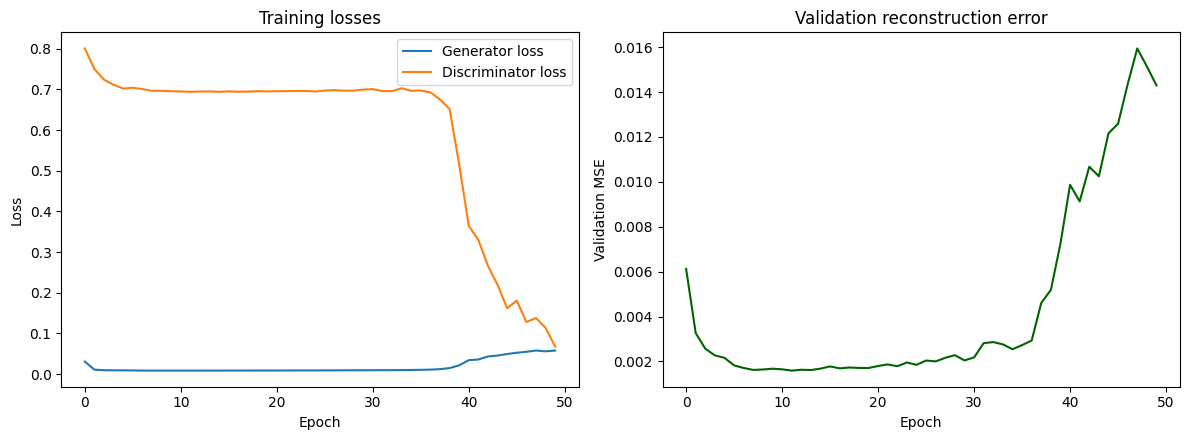


Final validation MSE: 0.01430
Best validation MSE: 0.00159 (epoch 12)


In [ ]:
# CELL 4 — TRAINING LOOP

mse_loss = nn.MSELoss()
bce_loss = nn.BCELoss()
ADV_WEIGHT = 0.01

gen_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
disc_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

N_EPOCHS = 50  # start here; increase if loss is still improving at the end

history = {"gen_loss": [], "disc_loss": [], "val_mse": []}

def evaluate_val_mse(gen, loader):
    """Plain reconstruction MSE on the validation set, no adversarial term.
    This is the number we track to see if the generator is actually learning
    the real relationship, not just fooling the discriminator."""
    gen.eval()
    total_mse = 0.0
    n_batches = 0
    with torch.no_grad():
        for coarse, fine, _ in loader:
            coarse, fine = coarse.to(device), fine.to(device)
            pred = gen(coarse)
            total_mse += mse_loss(pred, fine).item()
            n_batches += 1
    gen.train()
    return total_mse / n_batches

print("Starting training...\n")

for epoch in range(N_EPOCHS):
    epoch_gen_loss = 0.0
    epoch_disc_loss = 0.0
    n_batches = 0

    for coarse, fine, weed_mask in train_loader:
        coarse, fine = coarse.to(device), fine.to(device)
        batch_size = coarse.size(0)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # Train Discriminator
        disc_optimizer.zero_grad()

        real_pred = discriminator(coarse, fine)
        real_loss = bce_loss(real_pred, real_labels)

        fake_fine = generator(coarse).detach()  # detach: don't backprop into generator here
        fake_pred = discriminator(coarse, fake_fine)
        fake_loss = bce_loss(fake_pred, fake_labels)

        disc_loss = (real_loss + fake_loss) / 2
        disc_loss.backward()
        disc_optimizer.step()

        # Train Generator
        gen_optimizer.zero_grad()

        fake_fine = generator(coarse)  # fresh forward pass, this time keeping the graph
        fake_pred = discriminator(coarse, fake_fine)

        adv_loss = bce_loss(fake_pred, real_labels)  # generator wants discriminator fooled
        recon_loss = mse_loss(fake_fine, fine)        # generator wants faithful reconstruction

        gen_loss = recon_loss + ADV_WEIGHT * adv_loss
        gen_loss.backward()
        gen_optimizer.step()

        epoch_gen_loss += gen_loss.item()
        epoch_disc_loss += disc_loss.item()
        n_batches += 1

    avg_gen_loss = epoch_gen_loss / n_batches
    avg_disc_loss = epoch_disc_loss / n_batches
    val_mse = evaluate_val_mse(generator, val_loader)

    history["gen_loss"].append(avg_gen_loss)
    history["disc_loss"].append(avg_disc_loss)
    history["val_mse"].append(val_mse)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d}/{N_EPOCHS}  |  Gen loss: {avg_gen_loss:.5f}  |  "
              f"Disc loss: {avg_disc_loss:.5f}  |  Val MSE: {val_mse:.5f}")

print("\nTraining complete.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history["gen_loss"], label="Generator loss")
axes[0].plot(history["disc_loss"], label="Discriminator loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training losses")
axes[0].legend()

axes[1].plot(history["val_mse"], color="darkgreen")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation MSE")
axes[1].set_title("Validation reconstruction error")

plt.tight_layout()
plt.savefig("gan_training_curves.png", dpi=120)
plt.show()

print(f"\nFinal validation MSE: {history['val_mse'][-1]:.5f}")
print(f"Best validation MSE: {min(history['val_mse']):.5f} (epoch {history['val_mse'].index(min(history['val_mse']))+1})")

Starting training with best-checkpoint saving...

Epoch   1/50  |  Gen loss: 0.03732  |  Disc loss: 0.77004  |  Val MSE: 0.00674  <- best so far
Epoch   5/50  |  Gen loss: 0.00887  |  Disc loss: 0.70415  |  Val MSE: 0.00186  <- best so far
Epoch  10/50  |  Gen loss: 0.00859  |  Disc loss: 0.69589  |  Val MSE: 0.00159  <- best so far
Epoch  15/50  |  Gen loss: 0.00866  |  Disc loss: 0.69524  |  Val MSE: 0.00165
Epoch  20/50  |  Gen loss: 0.00879  |  Disc loss: 0.69692  |  Val MSE: 0.00164
Epoch  25/50  |  Gen loss: 0.00896  |  Disc loss: 0.69710  |  Val MSE: 0.00170

No improvement for 15 epochs, stopping early at epoch 26.

Training complete. Best validation MSE: 0.00151 at epoch 11
Best generator weights saved to best_generator.pt
Best generator weights reloaded into `generator`.


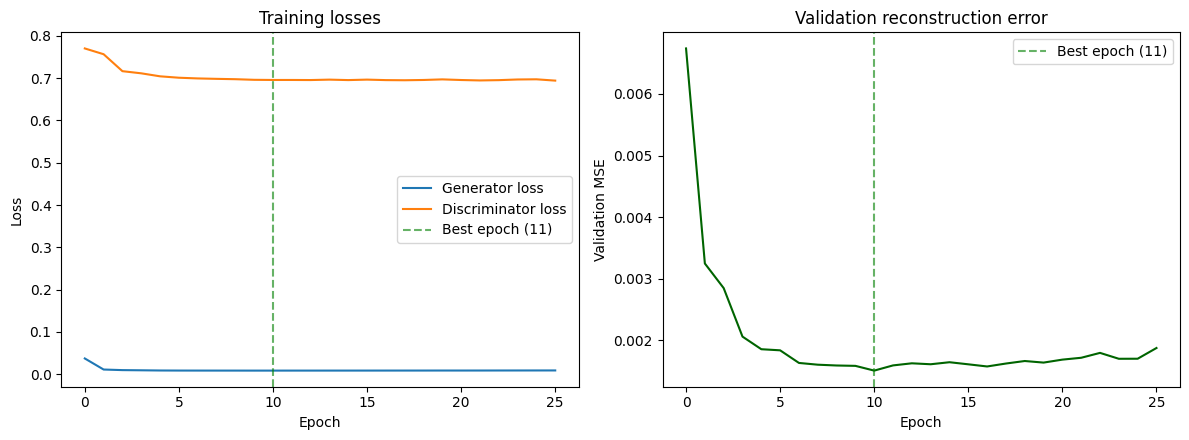

In [ ]:
# CELL 5 — RETRAIN WITH BEST-CHECKPOINT SAVING
# in the first run: the model reached its best point around
# epoch 13 (val MSE ~0.0016), then training became unstable -- the
# discriminator got too strong, and the generator's quality collapsed by
# epoch 50 (val MSE rose to ~0.017). This is a known GAN training dynamic,
# not a bug. The fix here is simple: track the best validation MSE seen
# so far, and save the generator's weights every time it improves, so we
# keep the best version regardless of what happens later in training.

generator = Generator(n_bands=6).to(device)
discriminator = Discriminator(n_bands=6).to(device)

gen_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
disc_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

N_EPOCHS = 50
PATIENCE = 15  # stop early if val MSE hasn't improved in this many epochs

history = {"gen_loss": [], "disc_loss": [], "val_mse": []}
best_val_mse = float("inf")
best_epoch = 0
epochs_without_improvement = 0

print("Starting training with best-checkpoint saving...\n")

for epoch in range(N_EPOCHS):
    epoch_gen_loss = 0.0
    epoch_disc_loss = 0.0
    n_batches = 0

    for coarse, fine, weed_mask in train_loader:
        coarse, fine = coarse.to(device), fine.to(device)
        batch_size = coarse.size(0)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # ---- Train Discriminator ----
        disc_optimizer.zero_grad()
        real_pred = discriminator(coarse, fine)
        real_loss = bce_loss(real_pred, real_labels)
        fake_fine = generator(coarse).detach()
        fake_pred = discriminator(coarse, fake_fine)
        fake_loss = bce_loss(fake_pred, fake_labels)
        disc_loss = (real_loss + fake_loss) / 2
        disc_loss.backward()
        disc_optimizer.step()

        # ---- Train Generator ----
        gen_optimizer.zero_grad()
        fake_fine = generator(coarse)
        fake_pred = discriminator(coarse, fake_fine)
        adv_loss = bce_loss(fake_pred, real_labels)
        recon_loss = mse_loss(fake_fine, fine)
        gen_loss = recon_loss + ADV_WEIGHT * adv_loss
        gen_loss.backward()
        gen_optimizer.step()

        epoch_gen_loss += gen_loss.item()
        epoch_disc_loss += disc_loss.item()
        n_batches += 1

    avg_gen_loss = epoch_gen_loss / n_batches
    avg_disc_loss = epoch_disc_loss / n_batches
    val_mse = evaluate_val_mse(generator, val_loader)

    history["gen_loss"].append(avg_gen_loss)
    history["disc_loss"].append(avg_disc_loss)
    history["val_mse"].append(val_mse)

    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        torch.save(generator.state_dict(), "best_generator.pt")
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        marker = "  <- best so far" if val_mse == best_val_mse else ""
        print(f"Epoch {epoch+1:3d}/{N_EPOCHS}  |  Gen loss: {avg_gen_loss:.5f}  |  "
              f"Disc loss: {avg_disc_loss:.5f}  |  Val MSE: {val_mse:.5f}{marker}")

    if epochs_without_improvement >= PATIENCE:
        print(f"\nNo improvement for {PATIENCE} epochs, stopping early at epoch {epoch+1}.")
        break

print(f"\nTraining complete. Best validation MSE: {best_val_mse:.5f} at epoch {best_epoch}")
print(f"Best generator weights saved to best_generator.pt")

generator.load_state_dict(torch.load("best_generator.pt"))
generator.eval()
print("Best generator weights reloaded into `generator`.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history["gen_loss"], label="Generator loss")
axes[0].plot(history["disc_loss"], label="Discriminator loss")
axes[0].axvline(best_epoch - 1, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training losses")
axes[0].legend()

axes[1].plot(history["val_mse"], color="darkgreen")
axes[1].axvline(best_epoch - 1, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation MSE")
axes[1].set_title("Validation reconstruction error")
axes[1].legend()

plt.tight_layout()
plt.savefig("gan_training_curves_v2.png", dpi=120)
plt.show()

=== Weed-specific evaluation on held-out test set ===

Number of test tiles with weed patches evaluated: 229
Number of test tiles' crop regions evaluated: 300

GAN model:
  Weed-region MSE:  0.004098  (std: 0.002059)
  Crop-region MSE:  0.001263  (std: 0.000768)

Naive baseline (coarse value copied to every cell):
  Weed-region MSE:  0.004261
  Crop-region MSE:  0.000972

GAN improvement over naive baseline:
  Weed regions: 3.8% lower error
  Crop regions: -30.0% lower error


/tmp/ipykernel_9626/1075696818.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([results['crop_errors'], results['weed_errors']], labels=["Crop regions", "Weed regions"])
/tmp/ipykernel_9626/1075696818.py:78: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


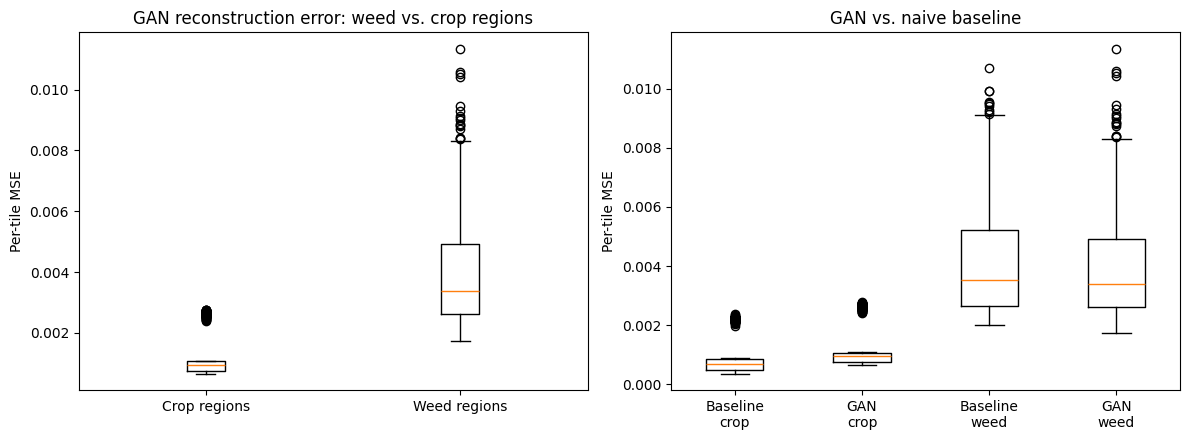

In [ ]:
# CELL 6 — WEED-SPECIFIC EVALUATION (does the weed survive super-scaling?)

generator.eval()

def evaluate_weed_vs_crop_error(gen, loader):
    """
    For every tile in the loader, compute MSE separately for:
      - cells inside the weed mask (weed_error)
      - cells outside the weed mask (crop_error)
    Only tiles that actually contain a weed patch are included in the
    weed_error calculation (a tile with zero weed cells would divide by zero).
    """
    weed_errors = []
    crop_errors = []
    baseline_weed_errors = []
    baseline_crop_errors = []

    with torch.no_grad():
        for coarse, fine, weed_mask in loader:
            coarse, fine, weed_mask = coarse.to(device), fine.to(device), weed_mask.to(device)
            pred = gen(coarse)

            baseline_pred = coarse.view(coarse.size(0), 6, 1, 1).expand(-1, -1, 30, 30)

            per_cell_sq_error = (pred - fine) ** 2
            baseline_sq_error = (baseline_pred - fine) ** 2

            per_cell_sq_error = per_cell_sq_error.mean(dim=1)
            baseline_sq_error = baseline_sq_error.mean(dim=1)

            for i in range(coarse.size(0)):
                mask = weed_mask[i].bool()
                n_weed_cells = mask.sum().item()

                if n_weed_cells > 0:
                    weed_errors.append(per_cell_sq_error[i][mask].mean().item())
                    baseline_weed_errors.append(baseline_sq_error[i][mask].mean().item())

                n_crop_cells = (~mask).sum().item()
                if n_crop_cells > 0:
                    crop_errors.append(per_cell_sq_error[i][~mask].mean().item())
                    baseline_crop_errors.append(baseline_sq_error[i][~mask].mean().item())

    return {
        "weed_errors": np.array(weed_errors),
        "crop_errors": np.array(crop_errors),
        "baseline_weed_errors": np.array(baseline_weed_errors),
        "baseline_crop_errors": np.array(baseline_crop_errors),
    }

results = evaluate_weed_vs_crop_error(generator, test_loader)

print("=== Weed-specific evaluation on held-out test set ===\n")
print(f"Number of test tiles with weed patches evaluated: {len(results['weed_errors'])}")
print(f"Number of test tiles' crop regions evaluated: {len(results['crop_errors'])}\n")

print(f"GAN model:")
print(f"  Weed-region MSE:  {results['weed_errors'].mean():.6f}  (std: {results['weed_errors'].std():.6f})")
print(f"  Crop-region MSE:  {results['crop_errors'].mean():.6f}  (std: {results['crop_errors'].std():.6f})")
print()
print(f"Naive baseline (coarse value copied to every cell):")
print(f"  Weed-region MSE:  {results['baseline_weed_errors'].mean():.6f}")
print(f"  Crop-region MSE:  {results['baseline_crop_errors'].mean():.6f}")
print()

weed_improvement = (1 - results['weed_errors'].mean() / results['baseline_weed_errors'].mean()) * 100
crop_improvement = (1 - results['crop_errors'].mean() / results['baseline_crop_errors'].mean()) * 100
print(f"GAN improvement over naive baseline:")
print(f"  Weed regions: {weed_improvement:.1f}% lower error")
print(f"  Crop regions: {crop_improvement:.1f}% lower error")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].boxplot([results['crop_errors'], results['weed_errors']], labels=["Crop regions", "Weed regions"])
axes[0].set_ylabel("Per-tile MSE")
axes[0].set_title("GAN reconstruction error: weed vs. crop regions")

axes[1].boxplot(
    [results['baseline_crop_errors'], results['crop_errors'],
     results['baseline_weed_errors'], results['weed_errors']],
    labels=["Baseline\ncrop", "GAN\ncrop", "Baseline\nweed", "GAN\nweed"]
)
axes[1].set_ylabel("Per-tile MSE")
axes[1].set_title("GAN vs. naive baseline")

plt.tight_layout()
plt.savefig("weed_specific_evaluation.png", dpi=120)
plt.show()

Starting training with weed-weighted loss...

Epoch   1/50  |  Gen loss: 0.03992  |  Val MSE (overall): 0.00593  |  Val MSE (weed only): 0.00677  <- best so far
Epoch   5/50  |  Gen loss: 0.01180  |  Val MSE (overall): 0.00301  |  Val MSE (weed only): 0.00671
Epoch  10/50  |  Gen loss: 0.01036  |  Val MSE (overall): 0.00185  |  Val MSE (weed only): 0.00526
Epoch  15/50  |  Gen loss: 0.01051  |  Val MSE (overall): 0.00195  |  Val MSE (weed only): 0.00604
Epoch  20/50  |  Gen loss: 0.01092  |  Val MSE (overall): 0.00195  |  Val MSE (weed only): 0.00566
Epoch  25/50  |  Gen loss: 0.01149  |  Val MSE (overall): 0.00239  |  Val MSE (weed only): 0.00717
Epoch  30/50  |  Gen loss: 0.01291  |  Val MSE (overall): 0.00284  |  Val MSE (weed only): 0.00618
Epoch  35/50  |  Gen loss: 0.02556  |  Val MSE (overall): 0.00846  |  Val MSE (weed only): 0.00895

No improvement for 15 epochs, stopping early at epoch 36.

Training complete. Best weed-region validation MSE: 0.00359 at epoch 21
Best weighted-

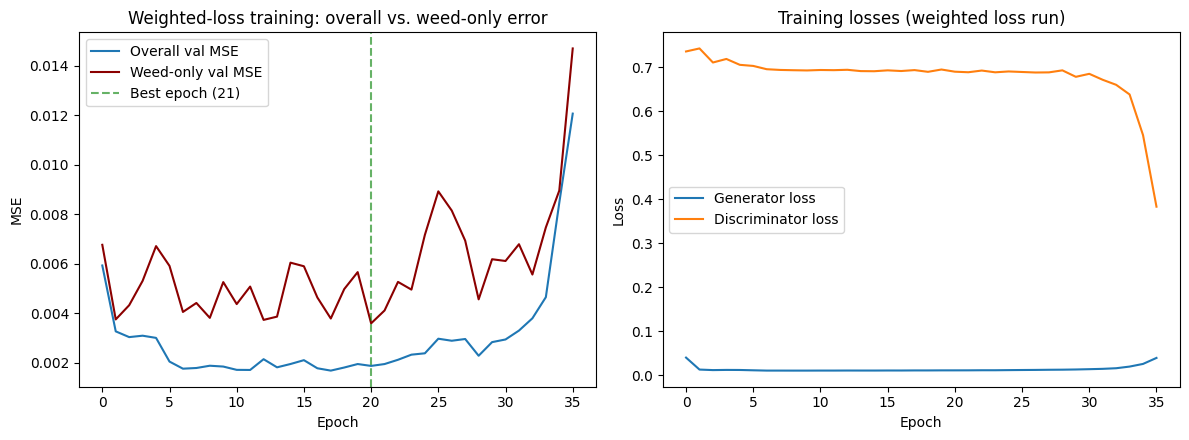

In [ ]:
# CELL 7 — RETRAIN WITH WEED-WEIGHTED LOSS
# The problem, confirmed by cell 6: weed cells are a small fraction of each
# tile's 900 cells (roughly 12-16% on average), so in a plain MSE loss, weed
# cells contribute very little to the total error signal. The model learns
# to get crop cells (the majority) right and treats weed cells as low
# priority, which is why weed-region MSE was worse than crop-region MSE and
# barely beat, or did not beat, the naive baseline.
#
# Fix: give weed cells more weight in the loss calculation so the model is
# explicitly pushed to prioritize weed detail, not just average error.

WEED_LOSS_WEIGHT = 5.0  # weed-cell errors count 5x as much as crop-cell errors in the loss

def weighted_mse_loss(pred, target, weed_mask, weed_weight=WEED_LOSS_WEIGHT):
    """
    pred, target: (B, 6, 30, 30)
    weed_mask: (B, 30, 30), 1.0 where weed, 0.0 where crop
    """
    per_cell_sq_error = ((pred - target) ** 2).mean(dim=1)  # (B, 30, 30)
    weight_map = 1.0 + (weed_weight - 1.0) * weed_mask       # (B, 30, 30)
    weighted_error = per_cell_sq_error * weight_map
    return weighted_error.mean()

generator = Generator(n_bands=6).to(device)
discriminator = Discriminator(n_bands=6).to(device)

gen_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
disc_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

N_EPOCHS = 50
PATIENCE = 15

history_weighted = {"gen_loss": [], "disc_loss": [], "val_mse": [], "val_weed_mse": []}
best_val_weed_mse = float("inf")
best_epoch = 0
epochs_without_improvement = 0

def evaluate_val_weed_mse(gen, loader):
    gen.eval()
    weed_errors = []
    with torch.no_grad():
        for coarse, fine, weed_mask in loader:
            coarse, fine, weed_mask = coarse.to(device), fine.to(device), weed_mask.to(device)
            pred = gen(coarse)
            per_cell_sq_error = ((pred - fine) ** 2).mean(dim=1)
            for i in range(coarse.size(0)):
                mask = weed_mask[i].bool()
                if mask.sum().item() > 0:
                    weed_errors.append(per_cell_sq_error[i][mask].mean().item())
    gen.train()
    return np.mean(weed_errors) if weed_errors else float("nan")

print("Starting training with weed-weighted loss...\n")

for epoch in range(N_EPOCHS):
    epoch_gen_loss = 0.0
    epoch_disc_loss = 0.0
    n_batches = 0

    for coarse, fine, weed_mask in train_loader:
        coarse, fine, weed_mask = coarse.to(device), fine.to(device), weed_mask.to(device)
        batch_size = coarse.size(0)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        disc_optimizer.zero_grad()
        real_pred = discriminator(coarse, fine)
        real_loss = bce_loss(real_pred, real_labels)
        fake_fine = generator(coarse).detach()
        fake_pred = discriminator(coarse, fake_fine)
        fake_loss = bce_loss(fake_pred, fake_labels)
        disc_loss = (real_loss + fake_loss) / 2
        disc_loss.backward()
        disc_optimizer.step()

        gen_optimizer.zero_grad()
        fake_fine = generator(coarse)
        fake_pred = discriminator(coarse, fake_fine)
        adv_loss = bce_loss(fake_pred, real_labels)
        recon_loss = weighted_mse_loss(fake_fine, fine, weed_mask)
        gen_loss = recon_loss + ADV_WEIGHT * adv_loss
        gen_loss.backward()
        gen_optimizer.step()

        epoch_gen_loss += gen_loss.item()
        epoch_disc_loss += disc_loss.item()
        n_batches += 1

    avg_gen_loss = epoch_gen_loss / n_batches
    avg_disc_loss = epoch_disc_loss / n_batches
    val_mse = evaluate_val_mse(generator, val_loader)
    val_weed_mse = evaluate_val_weed_mse(generator, val_loader)

    history_weighted["gen_loss"].append(avg_gen_loss)
    history_weighted["disc_loss"].append(avg_disc_loss)
    history_weighted["val_mse"].append(val_mse)
    history_weighted["val_weed_mse"].append(val_weed_mse)

    if val_weed_mse < best_val_weed_mse:
        best_val_weed_mse = val_weed_mse
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        torch.save(generator.state_dict(), "best_generator_weighted.pt")
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        marker = "  <- best so far" if val_weed_mse == best_val_weed_mse else ""
        print(f"Epoch {epoch+1:3d}/{N_EPOCHS}  |  Gen loss: {avg_gen_loss:.5f}  |  "
              f"Val MSE (overall): {val_mse:.5f}  |  Val MSE (weed only): {val_weed_mse:.5f}{marker}")

    if epochs_without_improvement >= PATIENCE:
        print(f"\nNo improvement for {PATIENCE} epochs, stopping early at epoch {epoch+1}.")
        break

print(f"\nTraining complete. Best weed-region validation MSE: {best_val_weed_mse:.5f} at epoch {best_epoch}")

generator.load_state_dict(torch.load("best_generator_weighted.pt"))
generator.eval()
print("Best weighted-loss generator weights reloaded into `generator`.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history_weighted["val_mse"], label="Overall val MSE")
axes[0].plot(history_weighted["val_weed_mse"], label="Weed-only val MSE", color="darkred")
axes[0].axvline(best_epoch - 1, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Weighted-loss training: overall vs. weed-only error")
axes[0].legend()

axes[1].plot(history_weighted["gen_loss"], label="Generator loss")
axes[1].plot(history_weighted["disc_loss"], label="Discriminator loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_title("Training losses (weighted loss run)")
axes[1].legend()

plt.tight_layout()
plt.savefig("gan_weighted_training_curves.png", dpi=120)
plt.show()

=== Weed-specific evaluation on held-out test set ===

Number of test tiles with weed patches evaluated: 229
Number of test tiles' crop regions evaluated: 300

GAN model:
  Weed-region MSE:  0.003637  (std: 0.001517)
  Crop-region MSE:  0.001721  (std: 0.000711)

Naive baseline (coarse value copied to every cell):
  Weed-region MSE:  0.004261
  Crop-region MSE:  0.000972

GAN improvement over naive baseline:
  Weed regions: 14.6% lower error
  Crop regions: -77.1% lower error


/tmp/ipykernel_9626/1075696818.py:74: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([results['crop_errors'], results['weed_errors']], labels=["Crop regions", "Weed regions"])
/tmp/ipykernel_9626/1075696818.py:78: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


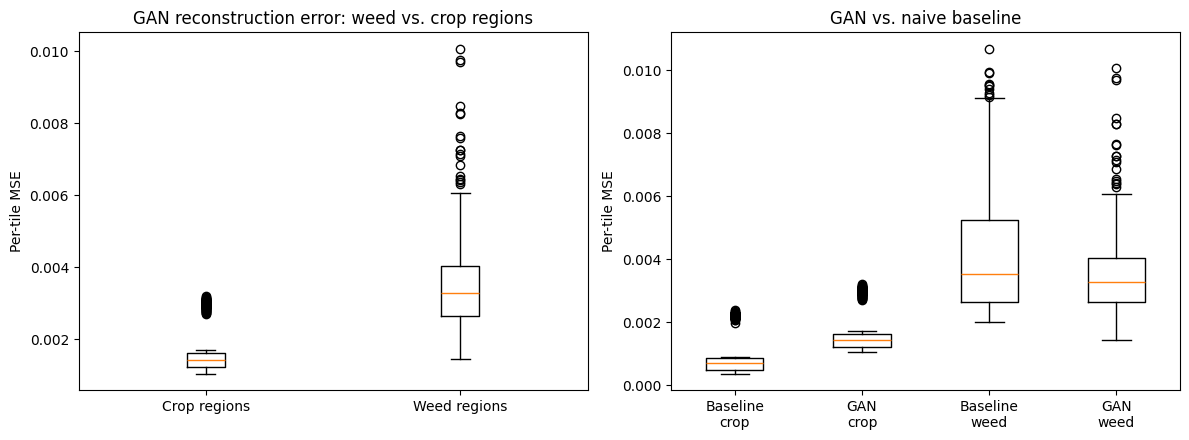

In [ ]:
# CELL 6 — WEED-SPECIFIC EVALUATION (does the weed survive super-scaling?)

generator.eval()

def evaluate_weed_vs_crop_error(gen, loader):
    """
    For every tile in the loader, compute MSE separately for:
      - cells inside the weed mask (weed_error)
      - cells outside the weed mask (crop_error)
    Only tiles that actually contain a weed patch are included in the
    weed_error calculation (a tile with zero weed cells would divide by zero).
    """
    weed_errors = []
    crop_errors = []
    baseline_weed_errors = []
    baseline_crop_errors = []

    with torch.no_grad():
        for coarse, fine, weed_mask in loader:
            coarse, fine, weed_mask = coarse.to(device), fine.to(device), weed_mask.to(device)
            pred = gen(coarse)

            baseline_pred = coarse.view(coarse.size(0), 6, 1, 1).expand(-1, -1, 30, 30)

            per_cell_sq_error = (pred - fine) ** 2
            baseline_sq_error = (baseline_pred - fine) ** 2

            per_cell_sq_error = per_cell_sq_error.mean(dim=1)
            baseline_sq_error = baseline_sq_error.mean(dim=1)

            for i in range(coarse.size(0)):
                mask = weed_mask[i].bool()
                n_weed_cells = mask.sum().item()

                if n_weed_cells > 0:
                    weed_errors.append(per_cell_sq_error[i][mask].mean().item())
                    baseline_weed_errors.append(baseline_sq_error[i][mask].mean().item())

                n_crop_cells = (~mask).sum().item()
                if n_crop_cells > 0:
                    crop_errors.append(per_cell_sq_error[i][~mask].mean().item())
                    baseline_crop_errors.append(baseline_sq_error[i][~mask].mean().item())

    return {
        "weed_errors": np.array(weed_errors),
        "crop_errors": np.array(crop_errors),
        "baseline_weed_errors": np.array(baseline_weed_errors),
        "baseline_crop_errors": np.array(baseline_crop_errors),
    }

results = evaluate_weed_vs_crop_error(generator, test_loader)

print("=== Weed-specific evaluation on held-out test set ===\n")
print(f"Number of test tiles with weed patches evaluated: {len(results['weed_errors'])}")
print(f"Number of test tiles' crop regions evaluated: {len(results['crop_errors'])}\n")

print(f"GAN model:")
print(f"  Weed-region MSE:  {results['weed_errors'].mean():.6f}  (std: {results['weed_errors'].std():.6f})")
print(f"  Crop-region MSE:  {results['crop_errors'].mean():.6f}  (std: {results['crop_errors'].std():.6f})")
print()
print(f"Naive baseline (coarse value copied to every cell):")
print(f"  Weed-region MSE:  {results['baseline_weed_errors'].mean():.6f}")
print(f"  Crop-region MSE:  {results['baseline_crop_errors'].mean():.6f}")
print()

weed_improvement = (1 - results['weed_errors'].mean() / results['baseline_weed_errors'].mean()) * 100
crop_improvement = (1 - results['crop_errors'].mean() / results['baseline_crop_errors'].mean()) * 100
print(f"GAN improvement over naive baseline:")
print(f"  Weed regions: {weed_improvement:.1f}% lower error")
print(f"  Crop regions: {crop_improvement:.1f}% lower error")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].boxplot([results['crop_errors'], results['weed_errors']], labels=["Crop regions", "Weed regions"])
axes[0].set_ylabel("Per-tile MSE")
axes[0].set_title("GAN reconstruction error: weed vs. crop regions")

axes[1].boxplot(
    [results['baseline_crop_errors'], results['crop_errors'],
     results['baseline_weed_errors'], results['weed_errors']],
    labels=["Baseline\ncrop", "GAN\ncrop", "Baseline\nweed", "GAN\nweed"]
)
axes[1].set_ylabel("Per-tile MSE")
axes[1].set_title("GAN vs. naive baseline")

plt.tight_layout()
plt.savefig("weed_specific_evaluation.png", dpi=120)
plt.show()

In [ ]:
!pip install terratorch==0.99.8 gdown tensorboard --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.4/40.4 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 102.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.6/317.6 kB 32.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.9/161.9 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.6/323.6 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 73.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.0/211.0 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.0/849.0 kB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━